In [2]:
import pandas as pd  # For data manipulation
import numpy as np   # For numerical operations
import matplotlib.pyplot as plt  # For plotting
import seaborn as sns  # For advanced visualizations

sns.set(style="whitegrid")

In [3]:
file_path = 'Walmart_Sales.csv' 
data = pd.read_csv(file_path)

data.head()

FileNotFoundError: [Errno 2] No such file or directory: 'Walmart_Sales.csv'

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   object 
 2   Weekly_Sales  6435 non-null   float64
 3   Holiday_Flag  6435 non-null   int64  
 4   Temperature   6435 non-null   float64
 5   Fuel_Price    6435 non-null   float64
 6   CPI           6435 non-null   float64
 7   Unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), object(1)
memory usage: 402.3+ KB


In [6]:
data.isnull().sum()

Store           0
Date            0
Weekly_Sales    0
Holiday_Flag    0
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
dtype: int64

In [24]:
unique_counts = data.apply(pd.Series.nunique)
print(unique_counts)

Store             45
Date             143
Weekly_Sales    6435
Holiday_Flag       2
Temperature     3528
Fuel_Price       892
CPI             2145
Unemployment     349
dtype: int64


In [7]:
data.describe()

,Store,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
count,6435.000000,6.435000e+03,6435.000000,6435.000000,6435.000000,6435.000000,6435.000000
mean,23.000000,1.046965e+06,0.069930,60.663782,3.358607,171.578394,7.999151
std,12.988182,5.643666e+05,0.255049,18.444933,0.459020,39.356712,1.875885
min,1.000000,2.099862e+05,0.000000,-2.060000,2.472000,126.064000,3.879000
25%,12.000000,5.533501e+05,0.000000,47.460000,2.933000,131.735000,6.891000
50%,23.000000,9.607460e+05,0.000000,62.670000,3.445000,182.616521,7.874000
75%,34.000000,1.420159e+06,0.000000,74.940000,3.735000,212.743293,8.622000
max,45.000000,3.818686e+06,1.000000,100.140000,4.468000,227.232807,14.313000


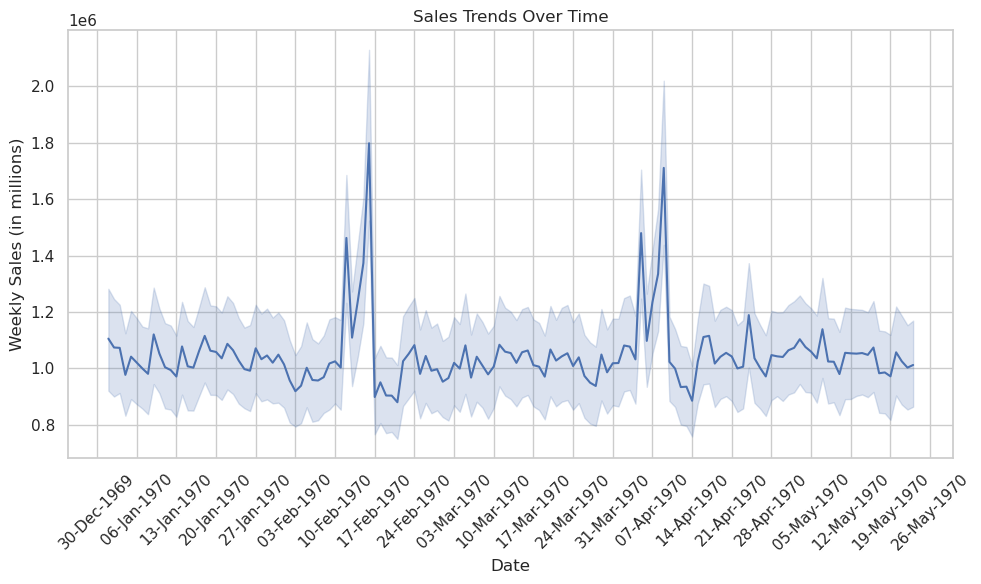

In [21]:
import matplotlib.dates as mdates

plt.figure(figsize=(10,6))
sns.lineplot(x='Date', y='Weekly_Sales', data=data)

plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d-%b-%Y'))  # Display day, month, year

plt.gca().xaxis.set_major_locator(mdates.WeekdayLocator(interval=1))

plt.xticks(rotation=45)

plt.title('Sales Trends Over Time')
plt.xlabel('Date')
plt.ylabel('Weekly Sales (in millions)')

plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(10,6))
sns.histplot(data['Weekly_Sales'], kde=True)

# Add title and labels
plt.title('Distribution of Weekly Sales')
plt.xlabel('Weekly Sales (in millions)')  # Adjusted for clarity
plt.ylabel('Number of Weeks')

# Show the plot
plt.tight_layout()
plt.show()

In [22]:
aggregated_data = data.groupby(['Date', 'Store']).agg({'Weekly_Sales': 'sum'}).reset_index()

print(aggregated_data.head())

         Date  Store  Weekly_Sales
0  01-04-2011      1    1495064.75
1  01-04-2011      2    1800171.36
2  01-04-2011      3     374556.08
3  01-04-2011      4    1900246.47
4  01-04-2011      5     314316.55


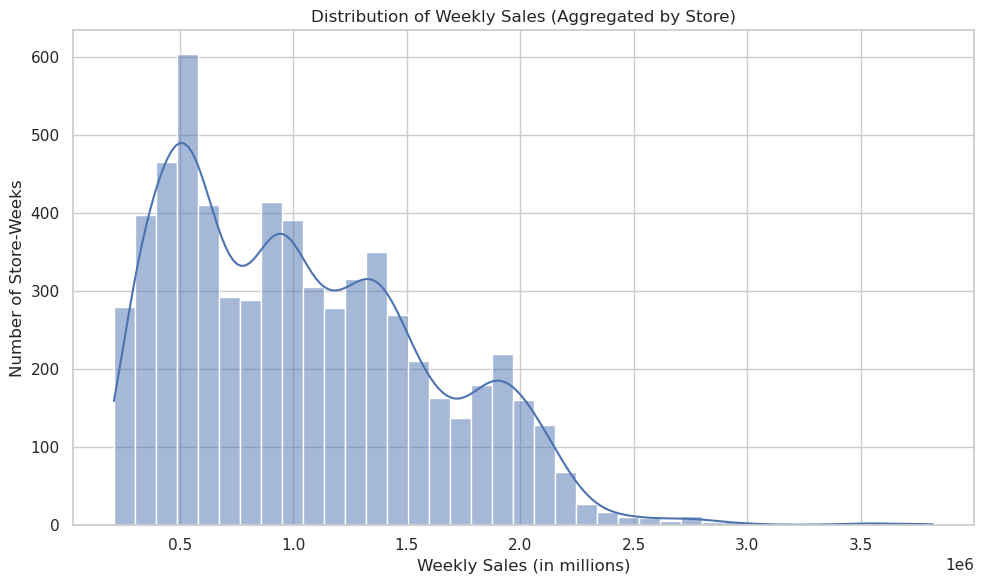

In [23]:
plt.figure(figsize=(10,6))
sns.histplot(aggregated_data['Weekly_Sales'], kde=True)

plt.title('Distribution of Weekly Sales (Aggregated by Store)')
plt.xlabel('Weekly Sales (in millions)')
plt.ylabel('Number of Store-Weeks')

plt.tight_layout()
plt.show()

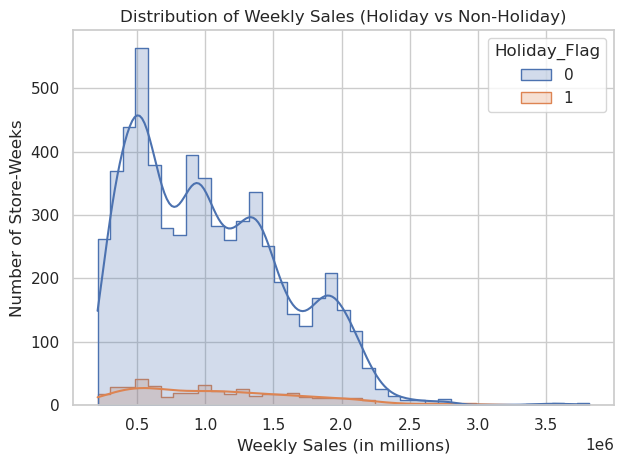

In [27]:
sns.histplot(data=data, x='Weekly_Sales', kde=True, hue='Holiday_Flag', element='step')
plt.title('Distribution of Weekly Sales (Holiday vs Non-Holiday)')
plt.xlabel('Weekly Sales (in millions)')
plt.ylabel('Number of Store-Weeks')
plt.tight_layout()
plt.show()